# P5 프로젝트: 서울 따릉이 대여

**K-means 군집화 | 단계별 데이터 분석 프로젝트**

> **핵심 문제:** 서울 따릉이 대여소를 이용 시간대에 따라 어떤 유형으로 구분할 수 있을까? 같은 대여소의 평일·주말 이용 패턴은 얼마나 다를까?

P1에서는 자전거 **대여량을 예측**했다. P5에서는 정답 레이블이 없는 대여소 데이터를 이용해 **비슷한 대여소를 발견**하고, 군집이 실제로 의미 있는지 판단한다.

이 프로젝트에서는 서로 다른 두 질문을 구분한다.

- **대여소 사이의 유사성:** A 대여소와 B 대여소의 평일·주말 대여·반납 패턴이 비슷한가?
- **한 대여소 안의 유사성:** A 대여소 자체의 평일 패턴과 주말 패턴이 비슷한가?

| 단계 | 해결할 문제 | 주요 결과물 |
|---|---|---|
| **1단계** | 분석 문제와 가설을 정한다 | 내가 세운 질문과 예상 |
| **2단계** | 데이터를 이해하고 패턴을 관찰한다 | 기초 통계·그래프·탐색 기록 |
| **3단계** | 군집화에 적절한 특성을 만든다 | 날짜 보정과 96개 시간대 비중 |
| **4단계** | 대여소 유형을 발견하고 군집을 검토한다 | 군집별 그래프·대표 대여소·시간대별 순유입 |
| **5단계** | 평일·주말의 유사성을 구분해 검토한다 | `day_gap`과 분리 군집화 |
| **6단계** | 결과를 검증하고 운영 방안을 제안한다 | 2025년 군집 해석과 운영 제안 |
| **7단계** | 2024년과 2025년의 이용 유형을 비교한다 | 공통 대여소·군집 변화와 검증 |

**진행 방식:** 제공된 핵심 코드를 먼저 실행하라. 각 단계에서 결과를 관찰하고, 일부 코드를 변경하거나 AI의 도움으로 새로운 분석을 시도하라. **AI가 제시한 결과나 해석을 그대로 제출하지 말고, 실제 출력과 대조한 뒤 자신의 근거를 기록하라.**

**사용 자료:** 서울시 공공자전거 대여이력에서 집계한 **2025년 및 2024년 실제 데이터** `p5_station_profiles_2025.csv`, `p5_station_profiles_2024.csv`를 사용한다. 전처리 과정에서 대여·반납이 각각 1,000건 이상이고 12개월 모두 대여 기록이 있는 대여소만 남겼으므로, 서울의 모든 대여소를 포함한 자료는 아니다. 두 파일 모두 GitHub에서 직접 불러온다.

**프로젝트 진행 원칙**

- **집계 단위를 분명히 하라.** 데이터 한 행은 대여소 한 곳이며, 여러 시간대의 대여·반납 기록을 요약한다.
- **이용 규모와 이용 패턴을 구분하라.** 대여가 많은 곳과 특정 시간에 대여가 집중되는 곳은 다른 개념이다.
- **평일·주말 날짜 수 차이를 보정하라.** 2025년은 월~금 261일, 토·일 104일이다(공휴일도 요일대로 구분).
- **군집 번호에 의미를 부여하지 마라.** `0`, `1`은 이름표일 뿐이다. 그래프를 본 뒤 잠정적인 유형 이름을 정하라.
- **관찰, 해석, 제안을 구분하라.** 군집화만으로 통근 목적이나 자전거 재배치 필요성을 증명할 수는 없다.

이 노트북에서는 학생이 직접 작성할 부분을 **`TODO`**, 해석을 기록할 부분을 **「프로젝트 기록」**, AI를 사용할 부분을 **「AI 체크포인트」**로 표시한다.

**코드 실행**

[(구글 코랩) P5 프로젝트: 서울 따릉이 대여](https://colab.research.google.com/github/codingalzi/code-workout-ml/blob/master/p5_project_seoul_bike.ipynb)에서 코드를 실행할 수 있다.

## 1단계 — 분석 문제와 가설을 정한다

### 어떤 대여소를 찾으려 하는가?

예를 들어 평일 출퇴근 시간에 대여가 집중되는 곳, 주말 낮 시간에 이용이 집중되는 곳, 평일과 주말의 패턴이 비슷한 곳이 있을 수 있다. **아직 실제로 존재한다고 단정하지 마라.** 데이터로 확인할 가설로만 사용하라.

**프로젝트 기록 — 시작 가설**

- 내가 구분해 보고 싶은 대여소 유형 두 가지:
- 유형마다 어떤 시간대에 대여 또는 반납이 집중될 것이라고 예상하는가?:
- 예상을 확인하려면 어떤 데이터가 필요한가?:
- 내 예상이 틀렸다고 판단할 수 있는 증거는 무엇인가?:

**AI 체크포인트 — 질문 다듬기**

AI에게 다음처럼 요청해도 된다.

> "서울 따릉이 대여소의 평일·주말 시간대별 대여·반납 자료로 K-means 분석을 할 것이다. 내가 세운 가설이 실제 데이터로 검증 가능한지 검토하고, 이를 확인할 그래프 두 개를 제안하라. 관찰할 사실과 추측을 구분하라."

AI의 제안 중 **현재 데이터만으로 확인할 수 없는 내용**을 하나 찾아 기록하라.

## 2단계 — 데이터의 구조와 이용 현황을 이해한다

### 데이터를 불러온다

한 행은 **2025년의 대여소 한 곳**을 나타낸다. 핵심 변수의 의미는 다음과 같다.

| 변수 | 의미 |
|---|---|
| `annual_rentals`, `annual_returns` | 해당 대여소의 연간 대여·반납 **총건수** |
| `m01`~`m12` | 해당 대여소의 1~12월 **대여 총건수** |
| `r_wd_h08` | 해당 대여소에서 **평일 오전 8시대**에 발생한 **연간 대여 총건수** |
| `b_we_h18` | 해당 대여소에서 **주말 오후 6시대**에 발생한 **연간 반납 총건수** |

`r`은 대여, `b`는 반납, `wd`는 평일, `we`는 주말, `h08`은 08:00~08:59를 뜻한다. **시간대별 값은 하루 평균이 아니다.** 날짜 수로 나누면 하루 평균을 구할 수 있다.

아래 코드는 [GitHub의 따릉이 데이터 폴더](https://github.com/codingalzi/code-workout-ml/tree/master/datasets/seoul_bike)에서 **2025년 집계 CSV를 인터넷으로 직접 읽는다.** 파일을 내려받아 노트북 폴더에 옮길 필요는 없다. 인터넷 연결이 필요하며, GitHub에 해당 CSV가 올라 있어야 한다.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

DATA_URL = "https://raw.githubusercontent.com/codingalzi/code-workout-ml/master/datasets/seoul_bike/"
bike = pd.read_csv(DATA_URL + "p5_station_profiles_2025.csv", dtype={"station_id": str})
bike.head()

,station_id,station_name,annual_rentals,annual_returns,m01,m02,m03,m04,m05,m06,...,b_we_h14,b_we_h15,b_we_h16,b_we_h17,b_we_h18,b_we_h19,b_we_h20,b_we_h21,b_we_h22,b_we_h23
0,00102,망원역 1번출구 앞,34539,36330,1562,1390,2493,3348,3859,3865,...,628,732,730,761,773,657,608,558,477,316
1,00103,망원역 2번출구 앞,26169,29316,1091,1083,2072,2589,3174,3172,...,645,684,758,776,791,671,551,495,420,280
2,00104,합정역 1번출구 앞,15621,13526,788,753,1342,1650,1685,1455,...,267,254,267,307,273,240,179,171,155,88
3,00105,합정역 5번출구 앞,8909,7284,459,390,816,985,882,839,...,125,124,172,175,196,172,124,109,119,67
4,00106,합정역 7번출구 앞,23371,22816,666,729,2076,2992,3152,2746,...,474,598,770,895,861,656,631,512,428,227


### 전체 이용 규모와 대여소 간 차이를 살펴본다

먼저 분석 대상 대여소가 몇 곳인지, 대여소별 이용량에 얼마나 차이가 있는지 확인하라. **대여건수와 반납건수를 더해 '전체 이동 횟수'라고 해석하지 마라.** 하나의 이용이 대여와 반납에 각각 기록되기 때문이다.

여기서 '전체'는 **현재 CSV에 포함된 대여소 전체**다. 실제 서울시 전체 대여소를 뜻하지 않을 수 있다.

In [2]:
print(f"분석 대여소: {len(bike):,}곳")
print(f"연간 대여: {bike['annual_rentals'].sum():,}건")
print(f"연간 반납: {bike['annual_returns'].sum():,}건")

bike[["annual_rentals", "annual_returns"]].describe().round(0)

분석 대여소: 2,583곳
연간 대여: 36,320,025건
연간 반납: 36,222,578건


,annual_rentals,annual_returns
count,2583.0,2583.0
mean,14061.0,14023.0
std,12208.0,12772.0
min,1037.0,1038.0
25%,6060.0,5392.0
50%,10619.0,10454.0
75%,18052.0,18368.0
max,162990.0,166035.0


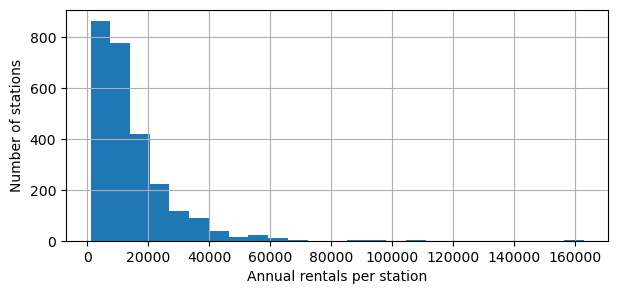

In [3]:
bike["annual_rentals"].hist(bins=25, figsize=(7, 3))
plt.xlabel("Annual rentals per station")
plt.ylabel("Number of stations")
plt.show()

**프로젝트 기록 — 이용 규모**

- 분석 대상 대여소 수와 연간 총대여건수:
- 대여소별 연간 대여건수의 평균과 중앙값:
- 평균과 중앙값이 차이 나는 이유에 대한 내 해석:
- 이용량만을 특성으로 사용한다면 어떤 군집이 형성될 것으로 예상하는가?:

### 평일과 주말의 하루 이용 패턴을 비교한다

2025년의 평일은 261일, 주말은 104일이다. 평일과 주말의 **연간 합계**를 바로 비교하면 날짜 수의 차이가 섞인다. 각 시간대의 총건수를 해당 요일 구분의 날짜 수로 나누어 **하루 평균**을 구하라.

아래 그래프에서 대여(Rental)와 반납(Return)의 시간대별 흐름을 관찰하라.

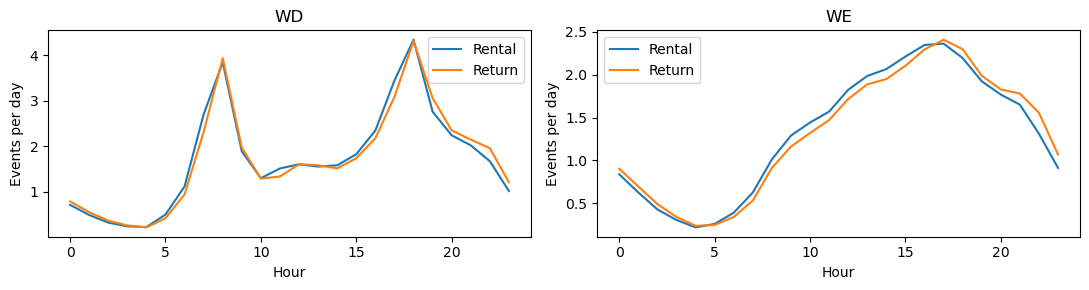

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, day, days in zip(axes, ["wd", "we"], [261, 104]):
    for kind, label in [("r", "Rental"), ("b", "Return")]:
        cols = [f"{kind}_{day}_h{h:02}" for h in range(24)]
        ax.plot(range(24), bike[cols].mean().to_numpy() / days, label=label)
    ax.set(title=day.upper(), xlabel="Hour", ylabel="Events per day")
    ax.legend()
plt.tight_layout()
plt.show()

### 나만의 탐색 질문을 만든다

제공된 그래프를 보고 **대여와 반납이 가장 다르게 보이는 시간대 한 곳**을 선택하라. 그 차이를 확인할 수 있는 추가 표나 그래프를 하나 만들어 보라.

**프로젝트 기록 — 나의 EDA**

- 내 질문:
- 이 질문을 확인할 변수와 그래프:
- 실제 관찰한 사실(숫자 또는 그래프 근거):
- 아직 확인할 수 없는 해석:

**AI 체크포인트 — 코드 도움과 해석 검증**

AI에게 다음처럼 요청해도 된다.

> "`bike`에는 대여소별 2025년 평일·주말 시간대별 대여·반납 총건수가 있다. 특정 시간대의 대여와 반납을 비교하는 짧은 pandas 또는 matplotlib 코드를 작성하라. 기존 코드의 변수명만 활용하고 불필요한 예외처리는 넣지 마라."

**AI가 만든 코드를 실행한 후** 실제 그래프가 질문에 답하는지 확인하고, 답하지 못한다면 수정하라.

In [5]:
# TODO: 나의 질문을 확인할 간단한 표 또는 그래프를 작성하라.
# 예: bike[["r_wd_h08", "b_wd_h08"]].describe()

**2단계 마무리 확인**

- [ ] 연간 총건수와 시간대별 총건수의 의미를 구분했다.
- [ ] 전체 이용 규모와 대여소별 이용 규모를 구분했다.
- [ ] 평일과 주말을 비교할 때 날짜 수를 보정해야 하는 이유를 설명했다.
- [ ] 나만의 질문 하나를 만들고 근거가 있는 답을 기록했다.

## 3단계 — 이용 규모보다 이용 패턴에 주목하도록 특성을 만든다

### 왜 건수를 비중으로 바꾸는가?

**K-means는 특성값의 차이가 작은 대여소끼리 묶는다.** 그런데 시간대별 대여건수를 그대로 사용하면, 실제 이용 시간대가 비슷하더라도 **대여량이 많은 곳과 적은 곳을 멀리 떨어진 대여소로 판단**할 수 있다.

예를 들어 두 시간대만 있다고 가정하자.

| 대여소 | 오전 대여 | 오후 대여 | 총대여 |
|---|---:|---:|---:|
| A | 800건 | 200건 | 1,000건 |
| B | 80건 | 20건 | 100건 |
| C | 20건 | 80건 | 100건 |

- **A와 B:** 대여량은 10배 차이 나지만, 모두 **오전 80%·오후 20%**로 이용 패턴이 같다.
- **B와 C:** 총대여량은 같지만, **언제 이용하는지**는 정반대이다.

건수를 그대로 비교하면 A와 B 사이의 차이가 B와 C 사이의 차이보다 훨씬 크다. **이 차이를 실제 거리로 계산해 보자.**

K-means는 특성값 사이의 **유클리드 거리**를 이용한다. 두 시간대의 대여건수를 좌표 $(오전,\ 오후)$로 나타내면, 두 대여소 $P=(p_1,p_2)$와 $Q=(q_1,q_2)$ 사이의 거리는 다음과 같다.

$$
d(P,Q)=\sqrt{(p_1-q_1)^2+(p_2-q_2)^2}
$$

**건수를 그대로 사용한 거리**를 계산하면 다음과 같다.

- **A와 B:** $d(A,B)=\sqrt{(800-80)^2+(200-20)^2}\approx 742.2$
- **B와 C:** $d(B,C)=\sqrt{(80-20)^2+(20-80)^2}\approx 84.9$

A와 B는 이용 시간대의 비율이 똑같은데도, 계산된 거리는 B와 C의 약 **8.7배**다. 즉, **건수를 그대로 사용하면 이용 패턴의 차이보다 이용 규모의 차이가 거리를 크게 좌우할 수 있다.**


하지만 건수를 비중으로 바꾸면 결과가 달라진다.

| 대여소 | 오전 비중 | 오후 비중 |
|---|---:|---:|
| A | 80% | 20% |
| B | 80% | 20% |
| C | 20% | 80% |

이제 **비중으로 바꾼 뒤의 거리**를 같은 방식으로 계산해 보자. A와 B는 모두 $(0.8,\ 0.2)$이고, C는 $(0.2,\ 0.8)$이다.

- **A와 B:** $d(A,B)=\sqrt{(0.8-0.8)^2+(0.2-0.2)^2}=0$
- **B와 C:** $d(B,C)=\sqrt{(0.8-0.2)^2+(0.2-0.8)^2}\approx 0.85$

이제 A와 B 사이의 거리는 **0**이고, 이용 시간대가 다른 B와 C 사이에는 거리가 남는다. **비중 변환을 하면 대여소의 이용 규모보다 시간대별 이용 패턴을 중심으로 비슷한 대여소를 찾을 수 있다.**

여기서는 계산을 이해하기 위해 시간대 **2개**만 사용했다. 실제 군집화에서는 날짜 수를 보정한 뒤 만든 **96개 특성**의 차이를 모두 이용해 거리를 계산한다.

**P5에서는 평일과 주말의 날짜 수 차이도 보정한다.** 2025년에는 평일이 261일, 주말이 104일이다. 따라서 평일·주말의 각 시간대 연간 총건수를 해당 날짜 수로 나누어 **하루 평균 대여·반납건수**를 먼저 계산한다. 그다음 한 대여소의 대여 48개 값을 합계로 나누어 비중으로 만들고, 반납 48개 값도 별도로 같은 과정을 거친다.

**평일과 주말을 모두 365로 나누면 어떻게 될까?** 예를 들어 평일과 주말에 하루 평균 100건씩 대여하는 대여소를 생각하자. 실제로는 하루 이용량이 같지만, 평일이 더 많으므로 연간 대여건수는 평일 **26,100건(100 × 261일)**, 주말 **10,400건(100 × 104일)**이 된다.

| 계산 방법 | 평일 하루 평균으로 간주한 값 | 주말 하루 평균으로 간주한 값 | 비중으로 바꾼 결과(평일 : 주말) |
|---|---:|---:|---:|
| **모두 365로 나누기** | 71.5건 | 28.5건 | **71.5% : 28.5%** |
| **각각 261일·104일로 나누기** | 100건 | 100건 | **50% : 50%** |

두 연간 총건수를 모두 365로 나누면 **평일과 주말의 날짜 수 차이가 그대로 남는다.** 나중에 48개 시간대 값의 합으로 다시 나누더라도, 공통으로 나눈 365는 약분되므로 결과가 달라지지 않는다. 결국 하루 이용량이 같은 대여소조차 **평일 이용이 더 집중된 것처럼 잘못 해석할 수 있다.**

그렇다면 **주말에 하루 평균 두 배 많이 이용하는 대여소**는 어떻게 나타날까? 평일에 하루 평균 100건, 주말에 하루 평균 200건을 대여한다고 가정하자.

| 구분 | 평일 | 주말 |
|---|---:|---:|
| 날짜 수 | 261일 | 104일 |
| 하루 평균 대여건수 | 100건 | 200건 |
| 연간 총대여건수 | 26,100건 | 20,800건 |

연간 총건수로만 보면 **평일 대여가 더 많다.** 하지만 하루를 기준으로 비교하면 **주말의 대여량이 평일의 두 배**다. 따라서 날짜 수를 보정한 뒤 비중을 계산하면 다음과 같다.

- **평일 비중의 합:** 100 ÷ (100 + 200) ≈ **0.33**
- **주말 비중의 합:** 200 ÷ (100 + 200) ≈ **0.67**

여기서 **0.67은 연간 대여건수의 67%가 주말에 발생했다는 뜻이 아니다.** 평일과 주말의 **하루 평균 이용량을 같은 기준에서 비교한 값**이다. 실제 연간 대여건수에서 주말이 차지하는 비율은 20,800 ÷ (26,100 + 20,800) ≈ **44.3%**다.

P5에서는 이 방법을 각 시간대에 적용한다. 그러면 **평일과 주말의 날짜 수 차이는 제거하면서, 주말에 하루 평균 더 많이 이용하는 특성과 하루 중 집중되는 시간대는 유지**할 수 있다.

- **대여 비중:** 평일 24개 + 주말 24개 = **48개** (합계 1)
- **반납 비중:** 평일 24개 + 주말 24개 = **48개** (합계 1)
- **K-means 입력:** 대여·반납 비중을 합친 **96개 특성**

**어떤 정규화를 선택했는지도 중요한 판단이다.** 특성마다 평균을 빼고 표준편차로 나누는 **표준화**와, 한 대여소의 시간대별 값들을 합계로 나누는 **비중 변환**은 목적이 다르다. P5에서는 대여소 간 **이용 규모보다 시간대별 구성**을 비교하고자 비중 변환을 선택했다. 따라서 모든 특성을 무조건 표준화하는 것이 아니라, **무엇을 비슷하다고 정의할지**에 맞게 변환 방법을 선택해야 한다.

**주의:** 여기서 계산한 비중은 *연간 총대여건수에 대한 비중*이 아니라, **평일·주말의 하루 평균값을 합한 값에 대한 비중**이다. 비중으로 바꾸면 이용 규모 정보는 군집화에서 대부분 제외되므로, **군집의 의미를 해석할 때 실제 대여·반납건수도 함께 확인**해야 한다.

In [6]:
rent_cols = [f"r_{d}_h{h:02}" for d in ("wd", "we") for h in range(24)]
return_cols = [f"b_{d}_h{h:02}" for d in ("wd", "we") for h in range(24)]

# 평일과 주말의 날짜 수 차이 보정
daily = bike[rent_cols + return_cols].astype(float).copy()
daily[rent_cols[:24] + return_cols[:24]] /= 261
daily[rent_cols[24:] + return_cols[24:]] /= 104

rent_share = daily[rent_cols].div(daily[rent_cols].sum(axis=1), axis=0)
return_share = daily[return_cols].div(daily[return_cols].sum(axis=1), axis=0)
X = pd.concat([rent_share, return_share], axis=1)
X.head()

,r_wd_h00,r_wd_h01,r_wd_h02,r_wd_h03,r_wd_h04,r_wd_h05,r_wd_h06,r_wd_h07,r_wd_h08,r_wd_h09,...,b_we_h14,b_we_h15,b_we_h16,b_we_h17,b_we_h18,b_we_h19,b_we_h20,b_we_h21,b_we_h22,b_we_h23
0,0.010216,0.006968,0.005036,0.003063,0.003104,0.003186,0.008756,0.008653,0.030462,0.036156,...,0.030882,0.035997,0.035898,0.037423,0.038013,0.032308,0.029899,0.027440,0.023457,0.015540
1,0.014830,0.011511,0.007389,0.004537,0.002385,0.001789,0.003007,0.009593,0.013456,0.021882,...,0.037648,0.039924,0.044243,0.045294,0.046169,0.039165,0.032161,0.028892,0.024515,0.016343
2,0.012695,0.008849,0.007274,0.006440,0.004865,0.003984,0.001807,0.009961,0.027381,0.019922,...,0.035953,0.034202,0.035953,0.041339,0.036760,0.032317,0.024103,0.023026,0.020871,0.011850
3,0.016125,0.012192,0.008888,0.005034,0.004405,0.001809,0.001966,0.009832,0.017226,0.014158,...,0.029908,0.029669,0.041153,0.041871,0.046896,0.041153,0.029669,0.026080,0.028472,0.016031
4,0.013890,0.011287,0.005969,0.004300,0.002376,0.001216,0.005714,0.013211,0.012617,0.008458,...,0.034049,0.042956,0.055312,0.064291,0.061848,0.047123,0.045327,0.036779,0.030745,0.016306


### 만든 특성의 의미를 해석한다

비중으로 바뀌면 값의 단위가 '건수'에서 '비율'로 달라진다. 다음 결과를 읽고 답하라.

In [7]:
print("군집화 특성 수:", X.shape[1])
print("대여 비중 합:", rent_share.iloc[0].sum().round(3))
print("반납 비중 합:", return_share.iloc[0].sum().round(3))
X.iloc[:3, :6].round(3)

군집화 특성 수: 96
대여 비중 합: 1.0
반납 비중 합: 1.0


,r_wd_h00,r_wd_h01,r_wd_h02,r_wd_h03,r_wd_h04,r_wd_h05
0,0.010,0.007,0.005,0.003,0.003,0.003
1,0.015,0.012,0.007,0.005,0.002,0.002
2,0.013,0.009,0.007,0.006,0.005,0.004


**프로젝트 기록 — 특성 설계의 판단 근거**

- 건수를 그대로 사용하면 어떤 대여소들이 비슷하다고 판단될 가능성이 큰가?:
- 시간대별 비중을 사용하면 무엇을 더 잘 비교할 수 있는가?:
- 날짜 수 보정을 생략하면 평일과 주말의 비교가 어떻게 달라지겠는가?:
- 대여·반납의 총규모 정보 중 비중 변환 뒤에는 직접 알 수 없는 것은 무엇인가?:

**AI 체크포인트 — 수식 검토**

> "평일·주말 시간대별 **연간 총건수**를 각각 261과 104로 나눈 뒤, 대여 48개와 반납 48개를 각각 합계 1로 만드는 이유를 설명하라. '비중은 연간 총건수 대비 비율'이라고 주장한다면 맞는지 검토하라."

AI의 설명이 실제 코드의 **분모**와 일치하는지 직접 확인하라.

## 4단계 — K-means로 대여소 유형을 발견한다

### 몇 개의 군집이 적절한가?

K-means는 **96개 특성을 종합하여 이용 패턴이 비슷한 대여소**를 같은 군집으로 묶는다. 먼저 군집 수 `k`를 2~6까지 바꾸어 **실루엣 점수**를 계산하라.

**실루엣 점수가 가장 높은 `k`를 코드가 자동으로 선택**하게 한다. 어떤 값이 선택되었는지 직접 확인하라. 단, 높은 점수는 군집 간 구분이 상대적으로 좋다는 뜻이지 **실제로 뚜렷한 이용 목적이 존재한다는 증거는 아니다.** 군집 크기와 시간대별 그래프도 살펴야 한다.

계산 시간을 줄이기 위해 실루엣 점수는 각 `k`에서 **대여소 500곳을 표본으로 추출해 계산**한다. 따라서 전체 대여소에 대해 계산한 점수와 조금 다를 수 있다.

In [8]:
results = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    score = silhouette_score(X, labels, sample_size=500, random_state=42)
    results.append([k, score])

scores = pd.DataFrame(results, columns=["k", "silhouette"])
scores

c:\Users\gslee\miniforge3\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
c:\Users\gslee\miniforge3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=11.
  warnings.warn(
c:\Users\gslee\miniforge3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than

,k,silhouette
0,2,0.397923
1,3,0.150857
2,4,0.140263
3,5,0.141498
4,6,0.103869


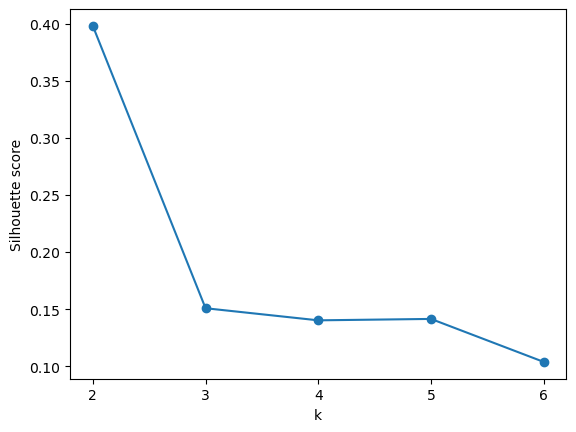

In [9]:
scores.plot(x="k", y="silhouette", marker="o", legend=False)
plt.xticks(scores["k"])
plt.ylabel("Silhouette score")
plt.show()

### 실루엣 점수로 군집 수를 자동 선택하고 패턴을 확인한다

앞에서 계산한 `scores`의 **최고 실루엣 점수**에 해당하는 군집 수를 `K`로 지정한다. 코드를 실행해 실제로 몇 개의 군집이 선택되는지 확인하라.

네 그래프는 평일 대여, 주말 대여, 평일 반납, 주말 반납의 **군집별 평균 비중**이다. 군집 번호는 임의로 붙은 표식이며, 연도를 바꾸거나 다시 학습하면 번호가 달라질 수도 있다.

**중요:** 그래프의 세로축은 *평일·주말 날짜 수를 보정한 시간대별 비중*이며, 대여소 한 곳의 하루 평균 **절대 건수**가 아니다.

선택된 군집 수: K=2


c:\Users\gslee\miniforge3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=11.
  warnings.warn(


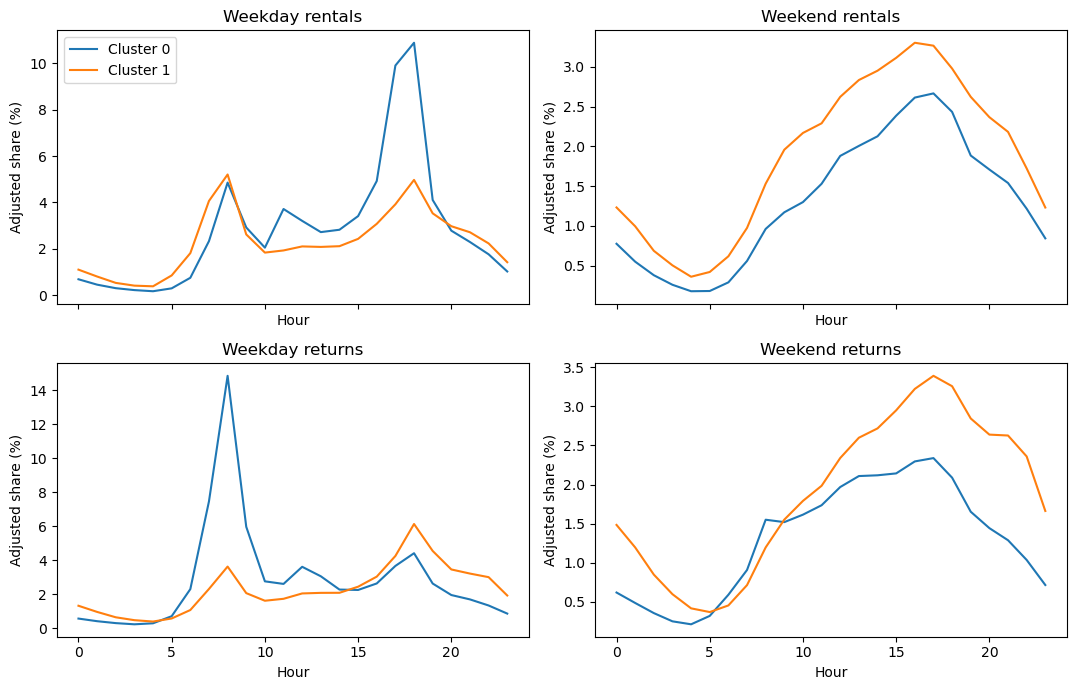

In [10]:
K = int(scores.loc[scores["silhouette"].idxmax(), "k"])
print(f"선택된 군집 수: K={K}")
model = KMeans(n_clusters=K, n_init=10, random_state=42)
bike = bike.copy()  # 새 열을 추가하기 전에 메모리 조각화를 줄인다.
bike["cluster"] = model.fit_predict(X)

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
parts = [rent_cols[:24], rent_cols[24:], return_cols[:24], return_cols[24:]]
titles = ["Weekday rentals", "Weekend rentals", "Weekday returns", "Weekend returns"]
for ax, cols, title in zip(axes.flat, parts, titles):
    for group, rows in X.groupby(bike["cluster"]):
        ax.plot(range(24), rows[cols].mean().to_numpy() * 100, label=f"Cluster {group}")
    ax.set(title=title, xlabel="Hour", ylabel="Adjusted share (%)")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

### 군집 이름을 바로 정하지 말고 증거부터 기록한다

각 군집의 **크기**와 **시간대별 특징**을 확인한 다음 잠정적인 이름을 붙여라. 예를 들어 '출근 대여 집중형'이라고 부르려면 다른 군집과 비교해 출근 시간대의 대여 비중이 높다는 그래프 근거가 필요하다.

In [11]:
bike["cluster"].value_counts().sort_index()

cluster
0     362
1    2221
Name: count, dtype: int64

**프로젝트 기록 — 군집 수와 유형 발견**

- `k`별 실루엣 점수와 **자동 선택된** `K`:
- 최고 점수의 군집 수가 적절한지에 대한 판단(군집 크기·그래프 근거):
- 가장 눈에 띄는 군집 두 개와 그 이유:
- 군집마다 임시로 붙인 이름과 그 증거:
- 실루엣 점수만으로는 답할 수 없는 질문 한 가지:

**AI 체크포인트 — 군집 이름 검토**

> "다음은 K-means 군집별 시간대 이용 비중 그래프에서 내가 관찰한 사실이다: [내 관찰 내용]. 각 군집에 잠정적인 이름을 제안하되, 통근·여가 목적을 확정하지 말고 이름의 근거와 반례 가능성을 함께 제시하라."

제안받은 이름 중 **데이터가 뒷받침하지 못하는 이름**이 있으면 수정하라.

### 군집 중심(센트로이드)과 실제 대여소를 비교한다

앞의 그래프에서 비슷한 이용 패턴을 가진 대여소들이 같은 군집으로 묶이는 것을 확인했다. **그렇다면 같은 군집에 속한 대여소들은 정말 모두 비슷할까?**

K-means는 군집마다 **중심점(centroid)**을 계산한다. 이는 해당 군집에 속한 대여소들의 **96개 특성값을 각각 평균한 패턴**이다. 중심점 자체가 실제 대여소인 것은 아니다.

각 대여소의 특성값을 자기 군집의 중심점과 비교하면 다음을 확인할 수 있다.

- **중심에 가까운 대여소:** 그 군집의 전형적인 이용 패턴을 보여주는 사례다.
- **중심에서 먼 대여소:** 같은 군집 안에서도 상대적으로 다른 이용 패턴을 가진 사례다.

`model.transform(X)`는 **각 대여소와 모든 군집 중심 사이의 거리**를 계산한다. 그중 가장 작은 값을 `center_gap`으로 저장한다. **값이 작을수록 군집 중심에 가깝다.** 앞의 `day_gap`과는 다른 지표이며, `center_gap`이 크다고 해서 잘못 군집화되었다는 뜻은 아니다.


In [12]:
bike["center_gap"] = model.transform(X).min(axis=1)

near = bike.loc[bike.groupby("cluster")["center_gap"].idxmin(),
                ["cluster", "station_name", "center_gap"]].assign(구분="중심에 가까움")
far = bike.loc[bike.groupby("cluster")["center_gap"].idxmax(),
               ["cluster", "station_name", "center_gap"]].assign(구분="중심에서 멂")

pd.concat([near, far]).sort_values(["cluster", "center_gap"])[
    ["cluster", "구분", "station_name", "center_gap"]
].round(3)

,cluster,구분,station_name,center_gap
243,0,중심에 가까움,DMC산학협력연구센터 앞,0.058
2563,0,중심에서 멂,국회박물관,0.488
848,1,중심에 가까움,석촌호수 서호 사거리,0.032
2268,1,중심에서 멂,국립중앙박물관 -용산가족공원 앞,0.240


표에 나타난 대여소 두 곳을 실제 그래프로 비교해 보자. 아래 그래프는 관심 군집의 **평일 대여 패턴**을 중심점 및 실제 대여소 두 곳에서 비교한다. `GROUP`을 다른 군집 번호로 바꾸어도 된다.

**주의:** 중심까지의 거리는 96개 특성을 모두 사용해 계산했다. 아래는 그중 **평일 대여 24개만** 보여주므로, 그래프가 비슷하더라도 주말·반납 패턴에서는 큰 차이가 있을 수 있다.


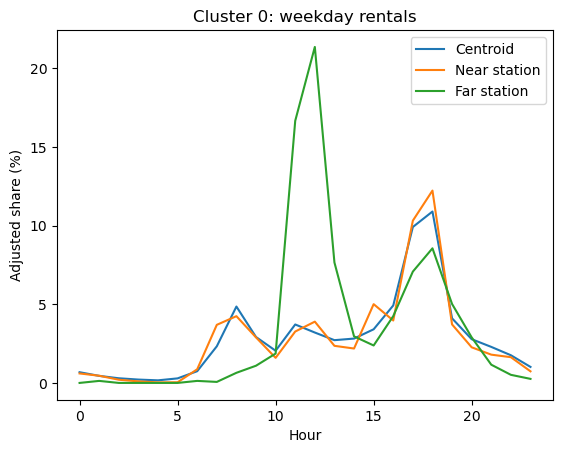

In [13]:
GROUP = 0  # TODO: 관심 있는 군집 번호로 바꾸어 보라.
selected = bike[bike["cluster"] == GROUP]
near_id = selected["center_gap"].idxmin()
far_id = selected["center_gap"].idxmax()
cols = rent_cols[:24]  # 평일 대여 24개 시간대

plt.plot(range(24), X.loc[selected.index, cols].mean().to_numpy() * 100, label="Centroid")
plt.plot(range(24), X.loc[near_id, cols].to_numpy() * 100, label="Near station")
plt.plot(range(24), X.loc[far_id, cols].to_numpy() * 100, label="Far station")
plt.title(f"Cluster {GROUP}: weekday rentals")
plt.xlabel("Hour")
plt.ylabel("Adjusted share (%)")
plt.legend()
plt.show()

### 군집마다 자전거가 모이거나 빠져나가는 시간대가 다른가?

군집은 **시간대별 이용 비중**으로 만들었으므로, 여기서는 실제 대여·반납 **건수**로 돌아가 군집별 특징을 더 살펴본다.

한 대여소에서 **순유입 = 반납건수 − 대여건수**로 계산하자.

- **양수:** 반납이 더 많아 해당 시간대에 자전거가 모이는 경향을 나타낸다.
- **음수:** 대여가 더 많아 해당 시간대에 자전거가 빠져나가는 경향을 나타낸다.
- **0에 가까움:** 대여와 반납 건수가 비슷하다.

2025년 평일은 261일이므로 각 시간대의 **연간 반납−대여 차이**를 261로 나누어 평일 하루 평균을 구한다. 그런 다음 군집별로 **대여소 한 곳당 평균 순유입**을 계산해 비교한다.

그래프에서 **어떤 군집이 오전에 음수이고 오후에 양수로 바뀌는지**, 혹은 그 반대인지 확인하라. 실제 자전거 부족·재배치 필요성을 판단하려면 자전거 재고, 거치대 수, 재배치 기록 등의 추가 자료가 필요하다.


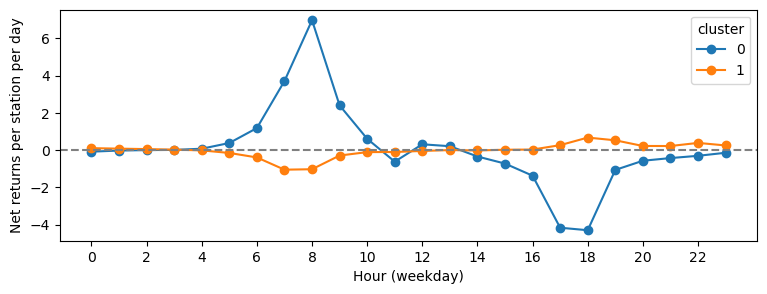

,8,18
cluster,,
0,7.0,-4.3
1,-1.0,0.7


In [14]:
net_wd = pd.DataFrame({
    h: (bike[f"b_wd_h{h:02}"] - bike[f"r_wd_h{h:02}"]) / 261
    for h in range(24)
})
net_by_cluster = net_wd.groupby(bike["cluster"]).mean()

net_by_cluster.T.plot(figsize=(9, 3), marker="o")
plt.axhline(0, color="gray", linestyle="--")
plt.xticks(range(0, 24, 2))
plt.xlabel("Hour (weekday)")
plt.ylabel("Net returns per station per day")
plt.show()

net_by_cluster[[8, 18]].round(1)  # 오전 8시와 오후 6시의 군집별 비교

**프로젝트 기록 — 발견한 군집을 검증하고 활용한다**

- 관심 군집에서 중심에 가까운 대여소와 먼 대여소의 이름:
- 두 대여소의 시간대별 패턴에서 발견한 공통점과 차이:
- 평일 오전·오후 순유입의 부호가 다르게 나타난 군집과 근거:
- 이 결과를 실제 운영에 적용하기 전에 확인해야 할 추가 자료:

**AI 체크포인트 — 군집 결과를 과장하지 않기**

> "다음은 내 군집별 순유입 그래프에서 관찰한 내용이다: [내 관찰]. 이 결과만으로 자전거 재배치가 필요하다고 결론 낼 수 있는지 검토하고, 부족한 자료를 알려 달라."

AI의 설명에서 **데이터가 직접 보여주는 사실**과 **추가 확인이 필요한 추측**을 구분하라.

**4단계 마무리 확인**

- [ ] 가장 높은 실루엣 점수로 `K`가 자동 선택되는 과정을 확인했다.
- [ ] 군집 번호가 아니라 **시간대별 패턴**으로 유형을 설명했다.
- [ ] 같은 군집의 대여소들이 실제로 모두 동일하다고 주장하지 않았다.
- [ ] 군집 중심과 가까운 대여소·먼 대여소를 비교했다.
- [ ] 군집별 순유입의 부호와 크기를 실제 건수로 해석했다.

## 5단계 — 평일·주말 유사성에 관한 두 질문을 구분한다

### 한 대여소 안에서 평일과 주말이 얼마나 다른가?

4단계에서는 **대여소 사이의 유사성**을 기준으로 군집을 만들고, 군집 중심과 순유입까지 확인했다. 이제 관점을 바꾸어 **같은 대여소의 평일 패턴과 주말 패턴**을 비교한다.

평일 대여 24개, 주말 대여 24개를 **각각 합계 1**로 변환하여 하루 중 어느 시간에 이용되는지를 비교한다. 반납도 동일하게 처리한다. 여기서는 **이용 시간대의 모양만 비교**하기 위해 평일·주말의 이용량 크기는 제외한다.

`day_gap`은 **평일 대여와 주말 대여의 시간대별 비중 차이**, 그리고 **평일 반납과 주말 반납의 시간대별 비중 차이**를 각각 0~1로 계산해 평균한 값이다. 두 비중 분포의 차이에서 절댓값의 합은 최대 2이므로, 코드에서는 대여·반납의 차이를 모두 더한 뒤 **4로 나눈다.** **0에 가까울수록 평일·주말의 시간대별 모양이 비슷하다.** 이는 군집 번호가 아니라 **개별 대여소의 특성**이다.

In [15]:
def day_pattern(day):
    blocks = []
    for kind in ("r", "b"):
        cols = [f"{kind}_{day}_h{h:02}" for h in range(24)]
        counts = bike[cols]
        blocks.append(counts.div(counts.sum(axis=1), axis=0))
    return pd.concat(blocks, axis=1)

weekday = day_pattern("wd")
weekend = day_pattern("we")
bike["day_gap"] = abs(weekday.to_numpy() - weekend.to_numpy()).sum(axis=1) / 4

pd.concat([bike.nsmallest(3, "day_gap"), bike.nlargest(3, "day_gap")])[["station_name", "day_gap"]]

,station_name,day_gap
1661,등나무 근린공원(시립북서울미술관 앞),0.070024
2001,한내 행복발전소 옆,0.074100
1961,철도교통관제센터 정문 앞,0.082735
1605,롯데 R&D 센터,0.540865
775,코오롱One&Only타워,0.539547
1164,벽산 디지털밸리 5차,0.508994


### 실제 대여소 두 곳을 골라 패턴을 비교한다

아래 코드는 `day_gap`이 가장 큰 대여소를 보여준다. `idxmax()`를 `idxmin()`으로 바꾸어 차이가 가장 작은 대여소도 확인하라.

이 그래프에서 평일·주말 각각의 비중 합은 1이다. 따라서 **이용 시간의 차이**를 보여주지만 **평일·주말의 총이용량 차이**를 직접 보여주지는 않는다.

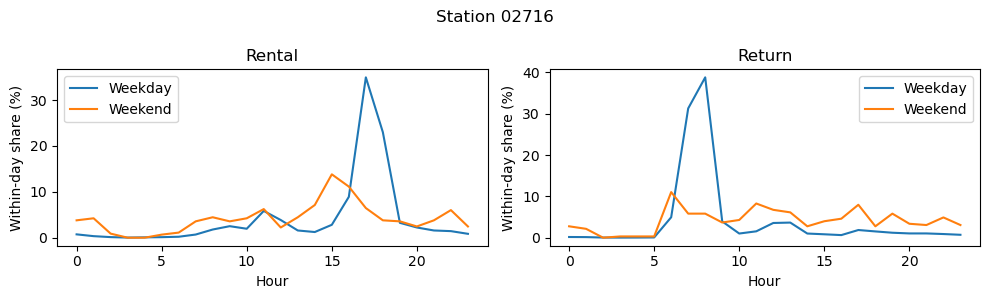

In [16]:
ROW = bike["day_gap"].idxmax()  # TODO: idxmin()으로 바꿔 비교
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, kind, title in zip(axes, ("r", "b"), ("Rental", "Return")):
    for day, label in (("wd", "Weekday"), ("we", "Weekend")):
        cols = [f"{kind}_{day}_h{h:02}" for h in range(24)]
        values = bike.loc[ROW, cols].to_numpy(dtype=float)
        ax.plot(range(24), values / values.sum() * 100, label=label)
    ax.set(title=title, xlabel="Hour", ylabel="Within-day share (%)")
    ax.legend()
plt.suptitle(f"Station {bike.loc[ROW, 'station_id']}")
plt.tight_layout()
plt.show()

### 같은 시간대 패턴이라도 주말 이용량은 다를 수 있다

`weekend_level`은 평일 하루 평균 대여량과 주말 하루 평균 대여량 가운데 **주말이 차지하는 비중**이다.

- `weekend_level = 0.5`: 평일과 주말의 하루 평균 대여량이 같다.
- `weekend_level > 0.5`: 주말의 하루 평균 대여량이 더 많다.
- `day_gap`은 **언제** 이용하는지, `weekend_level`은 **얼마나** 이용하는지에 관한 정보다.

두 지표가 서로 다른 질문에 답한다는 사실을 확인하라.

In [17]:
weekday_avg = bike[rent_cols[:24]].sum(axis=1) / 261
weekend_avg = bike[rent_cols[24:]].sum(axis=1) / 104
bike["weekend_level"] = weekend_avg / (weekday_avg + weekend_avg)

bike.groupby("cluster").agg(
    stations=("station_id", "size"),
    rentals=("annual_rentals", "median"),
    returns=("annual_returns", "median"),
    day_gap=("day_gap", "mean"),
    weekend_level=("weekend_level", "mean")
).round(3)

,stations,rentals,returns,day_gap,weekend_level
cluster,,,,,
0,362,11409.5,11779.5,0.301,0.315
1,2221,10498.0,10345.0,0.206,0.450


### 평일에 유사한 대여소가 주말에도 유사한가?

이 질문은 앞의 `day_gap`과도 다르다. **다른 대여소끼리** 평일 패턴만으로 한 번 군집화하고, 주말 패턴만으로 다시 군집화한다. 그 결과를 교차표로 비교하라.

- 같은 **행**: 평일 패턴이 유사한 대여소의 집합
- 같은 **열**: 주말 패턴이 유사한 대여소의 집합
- 같은 **칸**: 평일과 주말에서 각각 같은 군집에 속한 대여소 집합

**평일 군집 0과 주말 군집 0이 같은 의미라는 뜻은 아니다.** 두 모델은 각각 독립적으로 학습했다. 여기서는 비교를 쉽게 하기 위해 두 모델의 군집 수를 4단계에서 선택된 `K`와 같게 설정한다.

In [18]:
K_DAY = K  # 통합 군집화와 군집 수를 같게 두고 비교한다.
bike["weekday_group"] = KMeans(n_clusters=K_DAY, n_init=10, random_state=42).fit_predict(weekday)
bike["weekend_group"] = KMeans(n_clusters=K_DAY, n_init=10, random_state=42).fit_predict(weekend)
pd.crosstab(bike["weekday_group"], bike["weekend_group"])

c:\Users\gslee\miniforge3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=11.
  warnings.warn(
c:\Users\gslee\miniforge3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=11.
  warnings.warn(


weekend_group,0,1
weekday_group,,
0,168,509
1,1444,462


**프로젝트 기록 — 평일·주말 패턴 비교**

- `day_gap`이 큰 대여소와 작은 대여소에서 관찰한 차이:
- 한 대여소에서 평일과 주말의 **시간대 패턴이 유사하다**는 말의 의미:
- 평일에 **같은 군집인 두 대여소**가 주말에도 같은 군집인지 확인한 사례:
- `day_gap`과 `weekend_level`의 차이를 실제 수치로 설명:
- 평일·주말 분리 군집화 결과가 통합 군집화에서 놓치는 정보를 보여주었는가?:

**AI 체크포인트 — 유사성 개념 확인**

> "K-means의 군집 번호, `day_gap`, 평일·주말 분리 군집화의 교차표가 각각 무엇을 비교하는지 설명하라. 세 결과를 같은 의미로 혼동하면 어떤 오류가 생기는지 사례로 보여 달라."

AI가 **'평일 0번 군집 = 주말 0번 군집'**이라고 말하면 왜 잘못된 설명인지 직접 반박하라.

## 6단계 — 분석 결과를 검증하고 운영 방안을 제안한다

### 패턴 비중과 실제 이용 규모를 함께 살펴본다

4단계에서 군집별 순유입을 살펴봤다. 이번에는 관심 군집의 **대여·반납 건수 자체를 나란히** 확인한다. 시간대별 비중이 높다고 해서 그 시간대의 대여·반납 **절대 건수**가 큰 것은 아니다. 관심 있는 군집에서 **대여소 한 곳당 하루 평균 대여·반납건수**를 함께 확인하라.

어떤 시간대에 대여가 반납보다 많다면 자전거가 빠져나가는 경향을 시사할 수 있다. 그러나 **실제 재배치 필요성**은 이용 가능한 자전거 수, 거치대 용량, 운영·정비 기록 등 추가 자료가 있어야 판단할 수 있다.

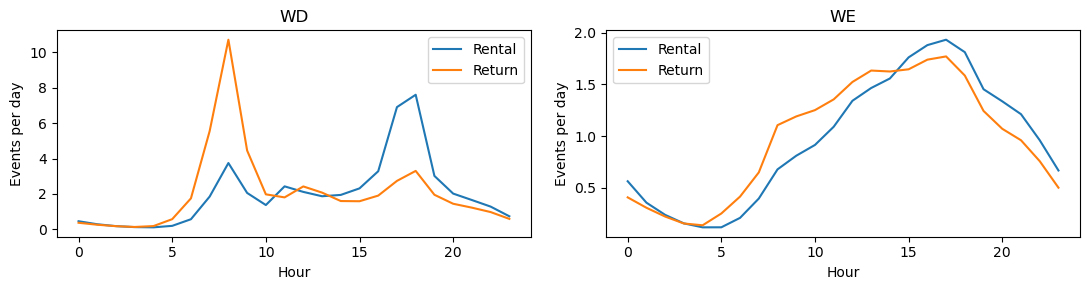

In [19]:
GROUP = 0  # TODO: 관심 있는 군집 번호
selected = bike[bike["cluster"] == GROUP]

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, day, days in zip(axes, ("wd", "we"), (261, 104)):
    for kind, label in (("r", "Rental"), ("b", "Return")):
        cols = [f"{kind}_{day}_h{h:02}" for h in range(24)]
        ax.plot(range(24), selected[cols].mean().to_numpy() / days, label=label)
    ax.set(title=day.upper(), xlabel="Hour", ylabel="Events per day")
    ax.legend()
plt.tight_layout()
plt.show()

### 월별 이용 패턴도 함께 확인한다

`m01`~`m12`는 **월별 대여 총건수**다. 월별 비중을 그리면 군집마다 계절적 집중 시기가 다른지 탐색할 수 있다. 다만 월별 날짜 수와 날씨 차이는 별도로 보정하지 않았으므로, **월별 비중을 계절의 인과효과로 해석하지 마라.**

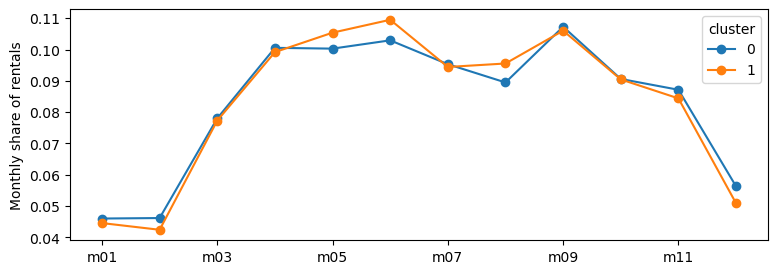

In [20]:
months = [f"m{m:02}" for m in range(1, 13)]
monthly_share = bike[months].div(bike["annual_rentals"], axis=0)
monthly_share.groupby(bike["cluster"]).mean().T.plot(marker="o", figsize=(9, 3))
plt.ylabel("Monthly share of rentals")
plt.show()

### 나의 추가 분석을 수행한다

다음 중 **하나를 선택**해 기존 결과를 다시 살펴보라.

- **A — 군집 수의 영향:** 현재 `K`는 최고 실루엣 점수로 자동 선택되었다. **다른 군집 수**로 별도 모델을 학습하면 군집 크기와 패턴에서 무엇이 추가되거나 사라지는지 비교하라. 기존 `model`과 `bike["cluster"]`는 바꾸지 마라.
- **B — 대여소의 차이:** 관심 군집에서 `day_gap`이 가장 큰 대여소와 가장 작은 대여소를 찾아 비교하라.
- **C — 운영 가설:** 대여·반납 시간대 차이가 두드러지는 군집을 선택하고, **수치 근거를 하나 이상** 제시하라.

복잡한 코드를 새로 작성할 필요는 없다. 기존 코드를 참고해 짧은 코드를 작성하거나 필요한 값만 바꾸라.

**AI 체크포인트 — 독립적인 분석 수행**

> "나는 P5에서 [선택한 A/B/C 활동]을 수행하려 한다. 기존 변수 `bike`, `X`, `model`은 유지하면서 **새 변수를 사용해** 간단한 코드를 제안하라. 그래프에서 무엇을 확인할지 먼저 질문하라. 결과는 임의로 만들어 내지 마라."

AI의 코드·해석을 검토하고, **스스로 수정한 부분**과 수정 이유를 남겨라.

In [21]:
# TODO: A/B/C 중 선택한 추가 분석을 작성하라.
# A 예시: test_model = KMeans(n_clusters=4, n_init=10, random_state=42)
#          pd.crosstab(bike["cluster"], test_model.fit_predict(X))

### 군집에 이름을 붙이고 근거 있는 운영 방안을 제안한다

아래 표를 **실제 출력과 그래프**를 보고 채워라. 2025년 데이터에서는 자동 선택된 `K`에 맞춰 작성하라. `K`가 달라지면 행을 조정하라.

| 군집 | 평일 특징(대여·반납) | 주말 특징(대여·반납) | `day_gap`·이용 규모 | 잠정적 이름과 근거 |
|---|---|---|---|---|
| 0 | | | | |
| 1 | | | | |

**프로젝트 기록 — 2025년 군집 해석과 운영 판단**

- 가장 높은 실루엣 점수로 **자동 선택된 `K`**를 기록하고, 군집 크기와 그래프도 적절한지 확인하라.
- **대여소 사이의 유사성**과 **한 대여소 안의 평일·주말 유사성**을 구분해 서술하라.
- 관심 군집 하나를 선택해 **시간대별 특징 → 운영 가설 → 필요한 추가 자료**를 연결하라.
- AI가 제안한 군집 이름 또는 운영 전략에서 **과장된 부분 하나**를 찾아 수정하라.
- **이번 데이터로 알 수 없는 것 두 가지**를 제시하라.

**해석의 경계:** K-means 군집은 이용 목적의 확정된 분류가 아니다. 시간대별 대여·반납 자료만으로는 실제 재고 부족이나 자전거 재배치 필요성을 단정할 수 없다. 이 결과는 **전처리 조건을 통과한 2025년 대여소**에 관한 것이므로, 서울의 모든 대여소로 확대해 단정하지 마라.

## 7단계 — 2024년과 2025년의 이용 유형을 비교한다

**새로운 질문:** 같은 대여소가 2024년에도 2025년과 비슷한 이용 유형을 보였을까?

2025년의 군집화를 **다시 학습하지 않고**, 이미 만든 `model`을 2024년 자료에도 적용한다. 두 연도를 같은 군집 기준으로 비교하기 위해서다. 이때 **군집 0·1은 2025년 모델이 정한 유형**을 뜻한다. 2024년에 별도의 모델을 학습해 붙인 번호와 혼동하지 마라.

분석 순서는 **공통 대여소 찾기 → 2024년 96개 특성 만들기 → 2025년 모델로 2024년 유형 판정 → 변화한 대여소 검토**다.

2024년은 윤년으로 **평일 262일, 주말 104일**, 2025년은 **평일 261일, 주말 104일**이다. 평일·주말의 날짜 수를 해당 연도에 맞게 보정해야 두 연도 자료를 같은 기준으로 비교할 수 있다. 아래 코드는 앞에서 정의한 `DATA_URL`을 사용해 **GitHub의 2024년 집계 CSV를 직접 읽는다.** 2단계의 데이터 불러오기 셀을 먼저 실행해야 한다.

### 두 연도에 공통으로 있는 대여소를 선택한다

같은 대여소의 이용 유형이 2024년에서 2025년으로 어떻게 달라졌는지 알아보려면, **두 연도에 모두 있는 대여소끼리만 비교**해야 한다. 한쪽 연도에만 있는 대여소는 변화 여부를 직접 비교할 수 없기 때문이다.

여기서 중요한 것은 **행의 순서가 아니라 대여소번호(`station_id`)를 기준으로 맞추는 것**이다. 두 CSV에서 같은 대여소가 같은 행에 있다는 보장은 없다. 단순히 첫 번째 행끼리 비교하면 서로 다른 대여소를 비교할 수도 있다.

이를 위해 다음 순서로 처리한다.

- `set_index("station_id")`로 대여소번호를 각 행의 **인덱스(식별 기준)**로 설정한다.
- `year24.index.intersection(year25.index)`로 **두 연도의 인덱스에 공통으로 있는 대여소번호만** 골라 `common_ids`에 저장한다.
- 이후 `year24.loc[common_ids]`와 `year25.loc[common_ids]`를 사용하면 **같은 대여소를 같은 순서로** 선택하여 비교할 수 있다.

예를 들어 2024년에 A·B·C 대여소가 있고 2025년에 B·C·D 대여소가 있다면, 비교 대상은 **B와 C만** 남는다. A와 D가 실제로 신설되거나 폐쇄되었다는 뜻은 아니다. 현재 데이터는 **연간 대여·반납 각각 1,000건 이상, 12개월 모두 대여 기록**이라는 조건을 만족하는 대여소만 포함하기 때문이다.

**주의:** 4단계의 K-means 모델은 2025년 전체 분석 대여소로 이미 학습했다. 여기서는 **연도별 비교 대상만 공통 대여소로 제한**하며, 모델을 다시 학습하지 않는다.

**확인할 것:** 두 연도의 공통 대여소는 몇 곳인가? 각 연도에만 있는 대여소는 몇 곳인가? 한쪽에만 있는 이유를 자료만으로 확정할 수 있을까?

In [22]:
bike24 = pd.read_csv(DATA_URL + "p5_station_profiles_2024.csv", dtype={"station_id": str})
year24 = bike24.set_index("station_id")
year25 = bike.set_index("station_id")
common_ids = year24.index.intersection(year25.index)

print(f"2024년 대여소: {len(year24):,}곳")
print(f"2025년 대여소: {len(year25):,}곳")
print(f"두 연도 공통 대여소: {len(common_ids):,}곳")

2024년 대여소: 2,548곳
2025년 대여소: 2,583곳
두 연도 공통 대여소: 2,473곳


### 2024년에도 같은 방식으로 96개 특성을 만든다

3단계의 코드를 다시 활용하되 **2024년의 평일 날짜 수는 262**로 바꾼다. 대여 48개와 반납 48개를 각각 합계 1로 만들어야 하며, **열의 이름과 순서도 2025년 `X`와 같아야** 이미 학습한 모델에 적용할 수 있다.

**TODO — 코드 확인:** 2025년 코드와 다른 부분을 찾아 표시하고, 왜 달라야 하는지 설명하라.

In [23]:
daily24 = year24.loc[common_ids, rent_cols + return_cols].astype(float).copy()
daily24[rent_cols[:24] + return_cols[:24]] /= 262  # 2024년 평일
daily24[rent_cols[24:] + return_cols[24:]] /= 104  # 2024년 주말

rent24 = daily24[rent_cols].div(daily24[rent_cols].sum(axis=1), axis=0)
return24 = daily24[return_cols].div(daily24[return_cols].sum(axis=1), axis=0)
X24 = pd.concat([rent24, return24], axis=1)

print("2024년 특성 수:", X24.shape[1])
print("2024년 첫 대여소의 대여·반납 비중 합:", round(rent24.iloc[0].sum(), 3), round(return24.iloc[0].sum(), 3))

2024년 특성 수: 96
2024년 첫 대여소의 대여·반납 비중 합: 1.0 1.0


### 2024년 자료를 2025년 군집 기준으로 분류한다

`model.predict(X24)`는 **2025년에 학습한 군집 중심을 그대로 사용하여 2024년의 각 대여소가 어느 유형에 가까운지 판정**한다. 이때 K-means를 새로 학습하지 않는다.

교차표에서 **행은 2024년 배정 유형**, **열은 2025년 배정 유형**이다. 대각선 값은 같은 군집으로 배정된 대여소 수, 대각선 바깥의 값은 다른 군집으로 배정된 대여소 수다.

**생각할 질문:** 같은 군집으로 배정된 비율이 높으면 두 연도의 이용 방식이 완전히 동일하다고 말할 수 있을까?

In [24]:
comparison = pd.DataFrame({
    "station_name": year25.loc[common_ids, "station_name"],
    "cluster_2024": model.predict(X24),
    "cluster_2025": year25.loc[common_ids, "cluster"]
}, index=common_ids)

pd.crosstab(comparison["cluster_2024"], comparison["cluster_2025"])

cluster_2025,0,1
cluster_2024,,
0,295,22
1,51,2105


### 유형이 바뀐 대여소를 직접 찾아본다

교차표만 보면 어떤 대여소에서 실제로 변화가 있었는지 알기 어렵다. **두 연도에 서로 다른 군집으로 배정된 대여소**를 찾아보자.

다음 셀에서 `changed`를 확인한 뒤, 다음 셀의 `STATION`을 관심 있는 대여소번호로 바꾸어 **평일 대여 시간대 패턴**을 비교하라. 필요하면 `cols`를 바꾸어 주말 대여나 평일 반납도 비교하라.

In [25]:
changed = comparison[comparison["cluster_2024"] != comparison["cluster_2025"]]
print(f"군집이 바뀐 대여소: {len(changed):,}곳")
print(f"같은 군집으로 배정된 비율: {(1 - len(changed) / len(comparison)):.1%}")
changed[["station_name", "cluster_2024", "cluster_2025"]].head(10)

군집이 바뀐 대여소: 73곳
같은 군집으로 배정된 비율: 97.0%


,station_name,cluster_2024,cluster_2025
station_id,,,
00222,시범아파트버스정류장 옆,0,1
00231,남부고용노동지청 남측,1,0
00239,유스호스텔 앞,1,0
00243,이앤씨드림타워 앞,0,1
00265,영등포유통상가 사거리,0,1
00266,영등포청과시장 사거리,1,0
00297,국회3문,1,0
00338,세운스퀘어 앞,1,0
00389,을지로4가역 1번출구,1,0


대여소: 시범아파트버스정류장 옆


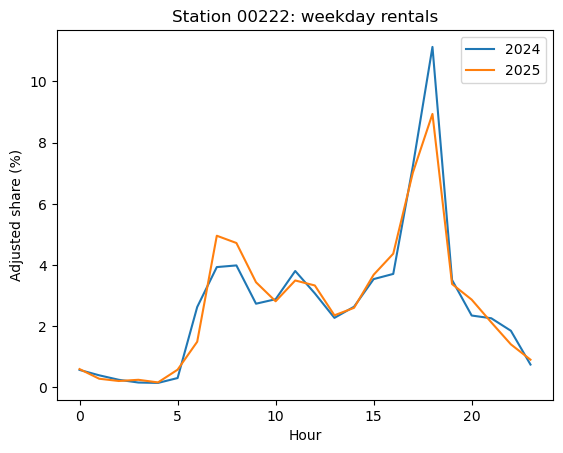

In [26]:
# TODO: 위 표에서 비교하고 싶은 대여소번호를 선택하라.
STATION = changed.index[0]
cols = rent_cols[:24]  # TODO: 다른 시간대 유형으로 바꿔 보라.

plt.plot(range(24), X24.loc[STATION, cols].to_numpy() * 100, label="2024")
plt.plot(range(24), X.loc[bike["station_id"] == STATION, cols].iloc[0].to_numpy() * 100, label="2025")
print("대여소:", comparison.loc[STATION, "station_name"])
plt.title(f"Station {STATION}: weekday rentals")
plt.xlabel("Hour")
plt.ylabel("Adjusted share (%)")
plt.legend()
plt.show()

**프로젝트 기록 — 연도별 비교**

- 두 연도에 공통으로 존재하는 대여소 수:
- 2024년과 2025년에 같은 군집으로 배정된 대여소의 비율:
- 내가 고른 대여소의 두 연도 군집 번호 및 시간대별 차이:
- 연도 사이에 **변화가 관찰되었다는 사실**과 **변화의 원인에 대한 추측**을 구분한 설명:
- 이용 패턴의 변화 여부를 더 확실하게 판단하기 위해 필요한 자료 한 가지:

**AI 체크포인트 — 연도 비교 해석 검증**

> "2025년 K-means 모델을 2024년 자료에 적용했다. 두 해의 군집 배정이 달라진 대여소를 찾았는데, 이를 곧바로 '이용 목적이 변했다'고 해석해도 되는가? 확인할 수 있는 사실과 추가 검증이 필요한 가설을 구분해 설명하라."

**주의:** 군집 번호가 같더라도 시간대별 비중이 조금 변했을 수 있고, 군집 번호가 바뀌어도 그 변화가 군집 경계 근처에서 발생했을 수 있다. 따라서 **배정 번호뿐 아니라 실제 24시간 그래프도 확인**하라. 연도 간 날씨·시설·운영 여건 등의 차이는 여기서 직접 통제하지 않았다.

원자료: [서울 열린데이터광장 — 공공자전거 대여이력](https://data.seoul.go.kr/dataList/OA-15182/F/1/datasetView.do).

### 최종 제출 전 확인

- [ ] 분석 질문과 사전 가설을 작성했다.
- [ ] 연간·월별 총건수와 시간대별 총건수의 의미를 구분했다.
- [ ] 평일·주말의 날짜 수를 보정한 이유를 설명했다.
- [ ] 이용건수를 비중으로 바꾸는 이유를 설명했다.
- [ ] 실루엣 점수가 가장 높은 `K`가 자동 선택되었는지 확인하고 그 의미를 설명했다.
- [ ] 군집별 대여·반납 패턴을 실제 그래프로 설명했다.
- [ ] 군집 중심에서 가까운 대여소와 먼 대여소를 비교했다.
- [ ] 군집별 평일 시간대 순유입 결과를 근거와 한계를 구분해 해석했다.
- [ ] `day_gap`과 `weekend_level`이 다른 정보를 뜻한다는 것을 이해했다.
- [ ] 통합 군집화와 평일·주말 분리 군집화가 답하는 질문을 구분했다.
- [ ] **2024·2025년 공통 대여소를 골라 같은 군집 기준으로 비교했다.**
- [ ] **두 연도의 군집이 달라진 대여소를 선택해 실제 시간대별 그래프로 확인했다.**
- [ ] AI가 작성한 코드나 해석을 직접 검증하고 수정한 내용을 기록했다.
- [ ] 운영 제안에 근거와 한계를 함께 제시했다.

### 평가 기준 (10점)

| 평가 영역 | 배점 | 확인할 내용 |
|---|---:|---|
| 문제 정의와 데이터 이해 | 1 | 분석 가설, 집계 단위, 탐색 결과 |
| 특성 설계와 군집 수 판단 | 2 | 날짜 수 보정, 비중 변환, 실루엣 기반 `K` 선택과 검토 |
| 군집 해석과 활용 | 2 | 군집별 시간대 패턴, 센트로이드, 시간대별 순유입 해석 |
| 평일·주말 유사성 비교 | 1 | `day_gap`, `weekend_level`, 분리 군집화 의미 구분 |
| 2024·2025년 비교 | 2 | 공통 대여소, 같은 모델 적용, 군집 변화와 시간대 그래프 검증 |
| AI 활용과 독립적 검증 | 1 | AI 제안 검토, 코드·해석 수정과 그 근거 |
| 운영 제안과 분석의 한계 | 1 | 자료에 근거한 제안, 과장된 해석 방지 |
| **합계** | **10** | |

**제출물:** 실행한 노트북과 요약 보고서 1~2쪽을 제출하라. **문제 정의 → 데이터 탐색 → 특성 설계 → 2025년 군집화 → 평일·주말 비교 → 운영 제안 → 2024·2025년 비교 → 종합 판단**의 흐름으로 정리하라.